<a href="https://colab.research.google.com/github/drishikaaneja/flyrank-ml-internship-starter/blob/main/work/notebooks/w06_validation_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# W06 · Validation and Research Claim Audit (ML-09)

**Lane:** CTR / Engagement Opportunity Scoring.

This notebook does two things. First, it reads two findings from FlyRank's research paper *The State of AI-Driven SEO in Numbers* (April 2026 edition) and asks the methodology question I would want asked of my own work. Then it turns the same lens on my Week-5 model.

Sections, in the skeleton's order:
1. Two paper findings + my methodology questions
2. My model under an honest split (before/after)
3. Leakage audit (including real failure examples)
4. Claim rewrite
5. Self-check

**Data:** same as Weeks 4–5, `fact_content_query_90d` (release `v20260703`) joined to `dim_content`. Section 2 also uses the last-30-day columns, but only as a **held-out future test window**, never as training input.

**How to run:** Colab secret `HF_TOKEN1` with notebook access on, then **Runtime → Run all**. Takes about 15–25 minutes (it trains 30 models).

## 1 · Two paper findings + my methodology questions

The paper is written for a broad audience and is open about its own standards: it says it is "a pattern study", that headline findings rely on direct aggregate comparisons, and that ML pages are exploratory. The questions below are the ones I would want a reviewer to ask about my own work, not a grade of the paper.

### Finding A: "The CTR Cliff" (Finding 3, Click Capture by Position Tier)

**What the paper reports:** weighted CTR (total clicks ÷ total impressions) by position tier: Top 3 **0.420%**, Page 1 (4–10) **0.340%**, Striking distance (11–20) **0.325%**, Page 3–5 **0.163%**, Deep **0.050%**, an 88% drop from top 3 to deep. The takeaway drawn is that improving a page already on page 1 "gets you more clicks faster" than rescuing a page on page 5. The appendix also reports a Kruskal–Wallis test for position tier → CTR (p < 0.001).

**My methodology question: at what level is "position" measured, and does the validation design support the causal takeaway?**
- If a page's tier comes from its *page-level* average position across all its queries, one page can mix a position-1 query with a position-40 query and land in the middle. In my own capstone, a page-level CTR-by-position curve looked wrong (pages averaging position 1 had lower CTR than position 4), while the *query-level* curve fell smoothly with position. The very small gap between Page 1 (0.340%) and Striking distance (0.325%) could partly reflect that blending. It would help to know whether the tiers are built from page-level or query-level positions.
- The tier comparison is cross-sectional: it compares different pages at different positions. The takeaway ("improving a page on page 1 gets more clicks faster") is about *changing* a page. A before/after comparison on pages whose snippets were actually changed (ideally against similar unchanged pages) would support that claim more directly. A significant Kruskal–Wallis test shows the tiers differ; it does not show what an intervention would do.

### Finding B: "Which Pages Will Grow?" (Part IV, Growth Prediction)

**What the paper reports:** a model trained on **96.6K pages that were clearly growing or declining** is right about **90%** of the time on unseen pages from the same brands and **75%** (range 64–85%) on brands it has never seen. The top predictor is **Days Visible** (0.161), followed by Days Since Update and Content Age. Elsewhere the paper defines trend direction as the last 30 days vs the 30 days before (>10% up or down).

**My methodology question: where does the label come from, and do the features share its time window?**
- The label is "growing vs declining", based on the last 30 days vs the previous 30. If features such as *Days Visible* or *Impressions per Visible Day* are counted over the last 90 days, that window **includes the 30 days the label is measured on**. A page that grew in the last month will also tend to have more visible days, so part of the "prediction" could be the label describing itself. Computing features only from days *before* the label window would answer this.
- Training only on pages that were **clearly** growing or declining removes the hard, middle cases. Accuracy on all pages, including stable ones, would show how the model behaves in real use.
- The paper deserves credit for testing on unseen brands. The drop from 90% (same brand) to 75% (new brands) is exactly the kind of gap a grouped split is meant to reveal, so the unseen-brand number is the more honest headline.

In [2]:
!pip install -q duckdb huggingface_hub

import os, json
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from google.colab import userdata
from scipy.stats import spearmanr
from sklearn.model_selection import GroupKFold, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

HF_TOKEN = userdata.get("HF_TOKEN1")          # Colab secret, never printed
BASE = "hf://datasets/FlyRank/internship-warehouse"
Q = f"{BASE}/fact_content_query_90d.parquet"
C = f"{BASE}/dim_content.parquet"

os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

con = duckdb.connect()
con.execute(f"CREATE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")

EXPECTED_ROWS = 1_995_557
MIN_PAGE_IMPRESSIONS_30D = 200
RANDOM_STATE = 42
print("Setup done")

Setup done


In [3]:
rows = con.sql(f"""
    SELECT q.client_hash_id, q.content_hash_id, q.query_hash_id,
           q.impressions_prev30  AS imp,   q.clicks_prev30  AS clicks,   q.avg_position_prev30 AS position,
           q.impressions_last30  AS imp_l, q.clicks_last30  AS clicks_l, q.avg_position_last30 AS position_l,
           q.query_token_count, q.query_char_count,
           c.word_count, c.content_type, c.main_intent, c.competition, c.search_volume
    FROM '{Q}' q
    LEFT JOIN '{C}' c USING (client_hash_id, content_hash_id)
    WHERE q.impressions_prev30 > 0 AND q.avg_position_prev30 >= 1
""").df()
print("Rows:", len(rows), "| expected (Weeks 4-5):", EXPECTED_ROWS, "| match:", len(rows) == EXPECTED_ROWS)

POS_BINS = [1, 2, 3, 4, 6, 11, 21, np.inf]
POS_LABELS = ["1", "2", "3", "4-5", "6-10", "11-20", "21+"]
FEATURES = ["position", "query_token_count", "query_char_count", "word_count",
            "content_type", "main_intent", "competition", "search_volume"]
CAT_COLS = ["content_type", "main_intent"]

cats = {c: pd.Categorical(rows[c]).categories for c in CAT_COLS}

def make_X(df, position_col):
    X = df[FEATURES].copy()
    X["position"] = df[position_col].values
    for c in CAT_COLS:
        X[c] = pd.Categorical(df[c], categories=cats[c])
    Xt = X.copy()
    for c in CAT_COLS:
        Xt[c] = Xt[c].cat.codes
    return X, Xt.astype(float).fillna(-1)

X_hgb, X_tree = make_X(rows, "position")
y = (rows["clicks"] / rows["imp"]).values
w = rows["imp"].values
rows["pos_band"] = pd.cut(rows["position"].round(), bins=POS_BINS, labels=POS_LABELS, right=False)

# Future window (last 30 days), used only as a held-out test set in setup C
fut_mask = (rows["imp_l"].fillna(0) > 0) & (rows["position_l"].fillna(0) >= 1)
print("Rows with last-30-day data (time-aware test pool):", int(fut_mask.sum()))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rows: 1995557 | expected (Weeks 4-5): 1995557 | match: True
Rows with last-30-day data (time-aware test pool): 1592536


## 2 · My model under an honest split (before/after)

My Week-5 model was a decision tree (chosen) with gradient boosting as the comparison, both judged against the position-band baseline. Here the same three methods, with the same features and settings, are run under three validation designs:

| Setup | Train on | Test on | Why |
|---|---|---|---|
| **A · Before: random row split** | random 80% of rows | the other 20% | The naive design. The same page and client appear on both sides, so it can flatter the model. |
| **B · After: grouped by client** | 4/5 of clients | the unseen 1/5 | My Week-5 design. Tests on clients the model has never seen. |
| **C · After: grouped + time-aware** | previous 30 days, training clients | **last 30 days, unseen clients** | The strictest: new clients *and* a later time period. |

Same metrics as Week 5, at page level (pages with at least 200 impressions in the test window): **page Spearman** (higher is better) and **page MAE in clicks** (lower is better).

**Reading note:** under the random split a page's queries are scattered across folds, so each test page is only a fragment of the real page. Page MAE is therefore much smaller in setup A and is **not comparable across setups**; compare MAE only *within* a setup (model vs baseline). Spearman is the fairer cross-setup comparison, and the clearest sign of leakage is the page-overlap figure printed below.

In [4]:
def page_eval(df_test, imp_col, click_col, pred_ctr):
    t = pd.DataFrame({"page": df_test["content_hash_id"].values,
                      "imp": df_test[imp_col].values,
                      "clicks": df_test[click_col].values})
    t["pred"] = t["imp"] * pred_ctr
    pg = t.groupby("page")[["imp", "clicks", "pred"]].sum()
    pg = pg[pg["imp"] >= MIN_PAGE_IMPRESSIONS_30D]
    return (float(spearmanr(pg["pred"], pg["clicks"]).correlation),
            float((pg["pred"] - pg["clicks"]).abs().mean()), int(len(pg)))

def fit_predict(tr_idx, X_hgb_te, X_tree_te, te_bands):
    tr = rows.iloc[tr_idx]
    band = tr.groupby("pos_band", observed=True)[["clicks", "imp"]].sum()
    band_ctr = (band["clicks"] / band["imp"]).to_dict()
    p_base = pd.Series(te_bands).map(band_ctr).astype(float).fillna(0).values

    tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=1000, random_state=RANDOM_STATE)
    tree.fit(X_tree.iloc[tr_idx], y[tr_idx], sample_weight=w[tr_idx])
    hgb = HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=200, random_state=RANDOM_STATE)
    hgb.fit(X_hgb.iloc[tr_idx], y[tr_idx], sample_weight=w[tr_idx])
    return {"baseline": p_base,
            "tree": np.clip(tree.predict(X_tree_te), 0, 1),
            "boosting": np.clip(hgb.predict(X_hgb_te), 0, 1)}

results = []
page_overlap = {}
oof_tree_B = np.full(len(rows), np.nan)

random_folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(rows))
group_folds = list(GroupKFold(n_splits=5).split(rows, groups=rows["client_hash_id"]))

# Setup A: random row split
for i, (tr, te) in enumerate(random_folds):
    if i == 0:
        page_overlap["A_random"] = float(rows["content_hash_id"].iloc[te].isin(set(rows["content_hash_id"].iloc[tr])).mean())
    preds = fit_predict(tr, X_hgb.iloc[te], X_tree.iloc[te], rows["pos_band"].iloc[te].values)
    for m, p in preds.items():
        s, mae, n = page_eval(rows.iloc[te], "imp", "clicks", p)
        results.append({"setup": "A_random", "fold": i + 1, "method": m, "page_spearman": s, "page_mae": mae, "pages": n})
    print(f"Setup A fold {i+1} done")

# Setup B: grouped by client
for i, (tr, te) in enumerate(group_folds):
    if i == 0:
        page_overlap["B_grouped"] = float(rows["content_hash_id"].iloc[te].isin(set(rows["content_hash_id"].iloc[tr])).mean())
    preds = fit_predict(tr, X_hgb.iloc[te], X_tree.iloc[te], rows["pos_band"].iloc[te].values)
    oof_tree_B[te] = preds["tree"]
    for m, p in preds.items():
        s, mae, n = page_eval(rows.iloc[te], "imp", "clicks", p)
        results.append({"setup": "B_grouped", "fold": i + 1, "method": m, "page_spearman": s, "page_mae": mae, "pages": n})
    print(f"Setup B fold {i+1} done")

# Setup C: grouped + time-aware (train previous 30 days, test last 30 days on unseen clients)
for i, (tr, te) in enumerate(group_folds):
    te_f = te[fut_mask.values[te]]
    df_te = rows.iloc[te_f]
    Xh_te, Xt_te = make_X(df_te, "position_l")
    bands_te = pd.cut(df_te["position_l"].round(), bins=POS_BINS, labels=POS_LABELS, right=False).values
    preds = fit_predict(tr, Xh_te, Xt_te, bands_te)
    for m, p in preds.items():
        s, mae, n = page_eval(df_te, "imp_l", "clicks_l", p)
        results.append({"setup": "C_grouped_time", "fold": i + 1, "method": m, "page_spearman": s, "page_mae": mae, "pages": n})
    print(f"Setup C fold {i+1} done")

res = pd.DataFrame(results)

Setup A fold 1 done
Setup A fold 2 done
Setup A fold 3 done
Setup A fold 4 done
Setup A fold 5 done
Setup B fold 1 done
Setup B fold 2 done
Setup B fold 3 done
Setup B fold 4 done
Setup B fold 5 done
Setup C fold 1 done
Setup C fold 2 done
Setup C fold 3 done
Setup C fold 4 done
Setup C fold 5 done


BEFORE / AFTER (mean of 5 folds)
                         page_spearman  page_mae
A_random       baseline         0.5408    2.0194
               tree             0.5590    2.0210
               boosting         0.5791    1.9285
B_grouped      baseline         0.6437    3.4384
               tree             0.6497    3.5364
               boosting         0.6559    3.6109
C_grouped_time baseline         0.6641    3.2818
               tree             0.6677    3.3161
               boosting         0.6728    3.3234

Folds (of 5) where the model beats the baseline:
                         spearman_wins  mae_wins
A_random       tree                  5         2
               boosting              5         5
B_grouped      tree                  4         3
               boosting              4         3
C_grouped_time tree                  4         2
               boosting              4         2

Share of test rows whose page also appears in training (fold 1): random split 99% |

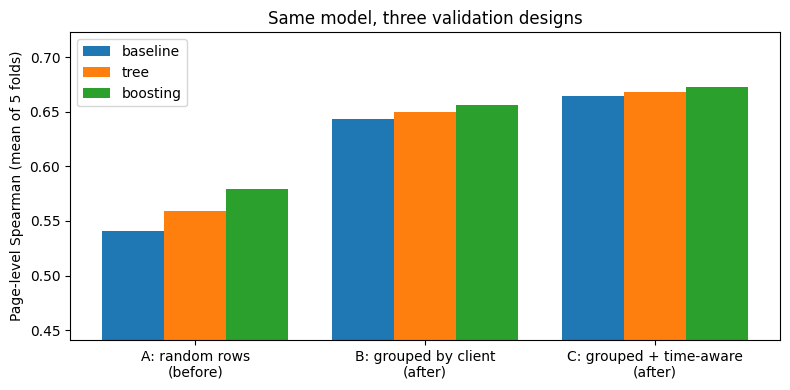

In [5]:
order_s = ["A_random", "B_grouped", "C_grouped_time"]
order_m = ["baseline", "tree", "boosting"]
ba = res.groupby(["setup", "method"])[["page_spearman", "page_mae"]].mean().reindex(
    pd.MultiIndex.from_product([order_s, order_m]))
print("BEFORE / AFTER (mean of 5 folds)")
print(ba.round(4).to_string())

def wins(setup, method, metric, higher):
    a = res[(res.setup == setup) & (res.method == method)].set_index("fold")[metric]
    b = res[(res.setup == setup) & (res.method == "baseline")].set_index("fold")[metric]
    return int((a > b).sum() if higher else (a < b).sum())

win_tbl = pd.DataFrame({
    (s, m): {"spearman_wins": wins(s, m, "page_spearman", True), "mae_wins": wins(s, m, "page_mae", False)}
    for s in order_s for m in ["tree", "boosting"]}).T
print("\nFolds (of 5) where the model beats the baseline:")
print(win_tbl.to_string())

print(f"\nShare of test rows whose page also appears in training (fold 1): "
      f"random split {page_overlap['A_random']:.0%} | grouped split {page_overlap['B_grouped']:.0%}")

# Optimism of the naive split, per method
optimism = {m: float(ba.loc[("A_random", m), "page_spearman"] - ba.loc[("B_grouped", m), "page_spearman"]) for m in order_m}
print("\nSpearman optimism of random split vs grouped split:", {k: round(v, 4) for k, v in optimism.items()})

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(order_s))
for k, (m, off) in enumerate(zip(order_m, [-0.27, 0, 0.27])):
    ax.bar(x + off, [ba.loc[(s, m), "page_spearman"] for s in order_s], 0.27, label=m)
ax.set_xticks(x); ax.set_xticklabels(["A: random rows\n(before)", "B: grouped by client\n(after)", "C: grouped + time-aware\n(after)"])
vals = ba["page_spearman"].values
ax.set_ylim(max(0, np.nanmin(vals) - 0.1), min(1, np.nanmax(vals) + 0.05))
ax.set_ylabel("Page-level Spearman (mean of 5 folds)")
ax.set_title("Same model, three validation designs")
ax.legend()
plt.tight_layout()
plt.savefig("work/figures/w06_before_after_split.png", dpi=150)
plt.show()

In [6]:
# Plain-language reading generated from the numbers above
def line_for(setup):
    b = ba.loc[(setup, "baseline")]; t = ba.loc[(setup, "tree")]; h = ba.loc[(setup, "boosting")]
    return (f"Spearman baseline {b.page_spearman:.3f}, tree {t.page_spearman:.3f}, boosting {h.page_spearman:.3f}; "
            f"MAE baseline {b.page_mae:.2f}, tree {t.page_mae:.2f}, boosting {h.page_mae:.2f}")

reading = [
    f"- A (random rows, before): {line_for('A_random')}.",
    f"- B (grouped by client, after): {line_for('B_grouped')}.",
    f"- C (grouped + time-aware, after): {line_for('C_grouped_time')}.",
    f"- Under the random split, {page_overlap['A_random']:.0%} of test rows belong to pages also seen in training; under the grouped split, {page_overlap['B_grouped']:.0%}.",
    "- Page MAE is not comparable across setups (random-split test pages are fragments); compare MAE only within a setup.",
]
opt_b = optimism["boosting"]
if opt_b > 0.005:
    reading.append(f"- The random split flatters boosting by {opt_b:+.3f} Spearman compared with the grouped split, so the naive design overstates it.")
elif opt_b < -0.005:
    reading.append(f"- The random split scores boosting {opt_b:+.3f} Spearman lower than the grouped split, so in this data the naive split did not inflate the headline metric; client mix between folds matters more.")
else:
    reading.append(f"- The random and grouped splits give almost the same boosting Spearman ({opt_b:+.3f}), so in this data the naive split did not noticeably inflate the headline metric.")
tw = win_tbl.loc[("C_grouped_time", "tree"), "spearman_wins"]
reading.append(f"- Under the strictest design (C), the tree beats the baseline on Spearman in {tw} of 5 folds.")
SPLIT_READING = "\n".join(reading)
print(SPLIT_READING)

- A (random rows, before): Spearman baseline 0.541, tree 0.559, boosting 0.579; MAE baseline 2.02, tree 2.02, boosting 1.93.
- B (grouped by client, after): Spearman baseline 0.644, tree 0.650, boosting 0.656; MAE baseline 3.44, tree 3.54, boosting 3.61.
- C (grouped + time-aware, after): Spearman baseline 0.664, tree 0.668, boosting 0.673; MAE baseline 3.28, tree 3.32, boosting 3.32.
- Under the random split, 99% of test rows belong to pages also seen in training; under the grouped split, 0%.
- Page MAE is not comparable across setups (random-split test pages are fragments); compare MAE only within a setup.
- The random split scores boosting -0.077 Spearman lower than the grouped split, so in this data the naive split did not inflate the headline metric; client mix between folds matters more.
- Under the strictest design (C), the tree beats the baseline on Spearman in 4 of 5 folds.


## 3 · Leakage audit

### 3a · Feature-by-feature review

| Feature | Source | Known at prediction time? | Derived from clicks / target? | Risk | Verdict |
|---|---|---|---|---|---|
| position | query table, same 30-day window as the target | Yes, reported alongside impressions | No | Position and CTR are measured in the same window; this is intended (CTR *given* position) | Keep |
| query_token_count, query_char_count | query text length | Yes, fixed | No | None | Keep |
| word_count | dim_content | Mostly; current snapshot, could have changed after an edit | No | Low: snapshot timing unknown | Keep, noted |
| content_type, main_intent | dim_content | Yes, fixed attributes | No | Low | Keep |
| competition, search_volume | keyword tool data in dim_content | Snapshot date unknown | No | Low: could be measured after the window | Keep, noted |
| *Not used:* clicks, CTR, any last-30-day column, `content_updated_date`, `last_optimized_date` | — | — | Clicks/CTR are the target; update dates may fall after the window | High | Excluded |

### 3b · Checks in code
1. **No target or future columns among the inputs.**
2. **No single feature predicts CTR suspiciously well** (a near-perfect single feature is a classic leak sign).
3. **Page overlap between train and test** under the random vs grouped split (shown in section 2).

In [7]:
forbidden = ["clicks", "ctr", "imp_l", "clicks_l", "position_l", "content_updated_date", "last_optimized_date"]
leak_cols = [f for f in FEATURES if f in forbidden]
print("Target or future columns among inputs:", leak_cols if leak_cols else "none")

single = []
for f in FEATURES:
    col = X_tree[f].values
    s = spearmanr(col, y).correlation
    single.append({"feature": f, "spearman_with_row_ctr": float(s)})
single = pd.DataFrame(single).sort_values("spearman_with_row_ctr", key=lambda s: s.abs(), ascending=False)
print("\nSingle-feature Spearman with row CTR (unweighted):")
print(single.round(3).to_string(index=False))
max_abs = float(single["spearman_with_row_ctr"].abs().max())
print(f"\nStrongest single-feature correlation: {max_abs:.2f} "
      f"({'suspicious, investigate' if max_abs > 0.9 else 'no single feature looks like a leak'})")

Target or future columns among inputs: none

Single-feature Spearman with row CTR (unweighted):
          feature  spearman_with_row_ctr
         position                 -0.186
       word_count                  0.014
      main_intent                  0.012
 query_char_count                 -0.007
     content_type                  0.004
    search_volume                 -0.004
      competition                 -0.003
query_token_count                  0.001

Strongest single-feature correlation: 0.19 (no single feature looks like a leak)


### 3c · Real failure examples

Using the Week-5 chosen model (decision tree) scored **out of fold under the grouped split (setup B)**, these are the five pages it most **over-predicted** (got far fewer clicks than expected) and the five it most **under-predicted** (got far more). Each row gets a one-line likely explanation from its own numbers. These are hypotheses to check, not proven causes.

In [8]:
r = rows[["content_hash_id", "query_hash_id", "imp", "clicks", "position", "content_type"]].copy()
r["pred"] = r["imp"].values * oof_tree_B
r["pos_x_imp"] = r["position"] * r["imp"]
pg = r.groupby("content_hash_id").agg(
    impressions=("imp", "sum"), clicks=("clicks", "sum"), predicted=("pred", "sum"),
    pos_x_imp=("pos_x_imp", "sum"), n_queries=("query_hash_id", "size"), top_query_imp=("imp", "max"),
    content_type=("content_type", "first")).reset_index()
pg = pg[pg["impressions"] >= MIN_PAGE_IMPRESSIONS_30D].copy()
pg["position"] = pg["pos_x_imp"] / pg["impressions"]
pg["top_query_share"] = pg["top_query_imp"] / pg["impressions"]
pg["residual"] = pg["clicks"] - pg["predicted"]

def explain(row):
    if row.clicks == 0:
        return "Zero clicks despite visibility: possible tracking gap or a result nobody chooses."
    if row.top_query_share >= 0.5:
        return f"One query brings {row.top_query_share:.0%} of impressions; the model can't see whether it is a brand or navigational search."
    if row.residual > 0 and row.position <= 3:
        return "Ranks near the top and beats the average CTR for its position; likely a strong title or a query the page answers exactly."
    if row.n_queries >= 500:
        return f"Spread over {int(row.n_queries)} queries; averaging many different searches makes the expectation rough."
    return "No single obvious cause in the available features; snippet quality or search features on the results page are not in the data."

cols = ["content_hash_id", "impressions", "clicks", "predicted", "position", "n_queries", "top_query_share", "residual"]
over = pg.nsmallest(5, "residual").copy()
under = pg.nlargest(5, "residual").copy()
for name, df in [("Most OVER-predicted (fewer clicks than expected)", over),
                 ("Most UNDER-predicted (more clicks than expected)", under)]:
    df["likely_reason"] = df.apply(explain, axis=1)
    print(name)
    print(df[cols].round(2).to_string(index=False))
    for _, rr in df.iterrows():
        print(f"  {rr.content_hash_id}: {rr.likely_reason}")
    print()
failures = pd.concat([over.assign(kind="over_predicted"), under.assign(kind="under_predicted")])

Most OVER-predicted (fewer clicks than expected)
         content_hash_id  impressions  clicks  predicted  position  n_queries  top_query_share  residual
content_943dc881428182b8       313923     155    2175.67      2.03        178             0.89  -2020.67
content_15168cd1c94e3529       133262      68    1146.58      3.26         72             0.13  -1078.58
content_4c15fe8dc370f3cd       106743      95    1019.67      2.92         57             0.17   -924.67
content_65c75874a23fca87       185572       5     532.18      8.19        111             0.54   -527.18
content_d0acf7062bc6b257       122357      15     503.18      2.06         61             0.98   -488.18
  content_943dc881428182b8: One query brings 89% of impressions; the model can't see whether it is a brand or navigational search.
  content_15168cd1c94e3529: No single obvious cause in the available features; snippet quality or search features on the results page are not in the data.
  content_4c15fe8dc370f3cd: No sing

## 4 · Claim rewrite

Claims I made earlier (capstone paper, Week 4, Week 5), checked against the evidence and rewritten in safe language: **observed**, **measured**, **directional** or **decision-support**.

| # | Original wording | Problem | Rewrite |
|---|---|---|---|
| 1 | "Click rate falls as position worsens" (capstone Figure 1 title) | Reads like a general law of search | **Observed** in this release: pooled query-level CTR falls with average position, from about 0.65% at position 1 to about 0.10% at position 10. |
| 2 | "Model ranks pages slightly better in every round" (capstone Figure 2) | True, but omits the size and the setting | **Measured** on 5 client-held-out folds: Spearman 0.709 vs 0.698, model ahead in 5 of 5 folds; the gap is small. |
| 3 | "Reviewing roughly the top 10% of under-performing pages addresses about 70% of the estimated gap" (capstone playbook) | "Addresses" implies the clicks would be recovered | **Measured:** the top 10% of under-performing pages account for 69.7% of *estimated* missing clicks. **Decision-support:** start reviews there; recovery is not tested. |
| 4 | "A title and meta description rewrite is the lowest-effort change with the clearest expected upside" (capstone, TOP3 pages) | No experiment supports "clearest expected upside" | **Decision-support:** for top-3 pages with low CTR, try a title/description rewrite first and measure clicks before and after; the upside is untested. |
| 5 | "The flags describe lasting gaps rather than one-month blips" (Week 4) | Fine as stated, but easy to over-read as "fixable" | **Observed:** all 50 of the top-50 flagged pages were still below expected clicks in the next 30 days. This shows persistence, not that a fix would work. |
| 6 | "The model relies most on query length in words" (Week 5) | Could be read as "query length causes CTR" | **Measured:** shuffling query length increased the model's error the most; this describes the model's behaviour, not a cause of CTR. |
| 7 | "Missing clicks" (throughout) | Sounds like clicks the page is owed | **Directional:** the gap between actual clicks and what pages with similar positions and features received in this data. |

The cell below adds the sentence this notebook supports about my own validation.

In [9]:
b_tree = ba.loc[("B_grouped", "tree")]; b_base = ba.loc[("B_grouped", "baseline")]
c_tree = ba.loc[("C_grouped_time", "tree")]; c_base = ba.loc[("C_grouped_time", "baseline")]
NEW_CLAIM = (f"Measured: under a client-grouped split the chosen tree reaches page Spearman {b_tree.page_spearman:.3f} "
             f"vs baseline {b_base.page_spearman:.3f}; on unseen clients in a later 30-day window it reaches "
             f"{c_tree.page_spearman:.3f} vs {c_base.page_spearman:.3f}. Directional, decision-support only.")
print(NEW_CLAIM)
CLAIMS_REWRITTEN = 7

Measured: under a client-grouped split the chosen tree reaches page Spearman 0.650 vs baseline 0.644; on unseen clients in a later 30-day window it reaches 0.668 vs 0.664. Directional, decision-support only.


## 5 · Self-check

In [10]:
metrics = {
    "assignment": "ML-09 Validation and Research Claim Audit",
    "lane": "CTR / Engagement Opportunity Scoring",
    "release": "v20260703",
    "paper": "FlyRank, The State of AI-Driven SEO in Numbers (April 2026)",
    "paper_findings_reviewed": ["Finding 3: CTR by position tier", "Part IV: Which Pages Will Grow? (growth prediction)"],
    "rows": int(len(rows)),
    "rows_future_window": int(fut_mask.sum()),
    "setups": {"A_random": "random 5-fold row split (before)",
               "B_grouped": "5-fold GroupKFold by client (after)",
               "C_grouped_time": "GroupKFold by client; train previous 30 days, test last 30 days (after)"},
    "before_after_mean": {f"{s}|{m}": {k: float(v) for k, v in ba.loc[(s, m)].items()} for s in order_s for m in order_m},
    "wins_vs_baseline": {f"{s}|{m}": {k: int(v) for k, v in win_tbl.loc[(s, m)].items()} for s in order_s for m in ["tree", "boosting"]},
    "page_overlap_fold1": page_overlap,
    "spearman_optimism_random_vs_grouped": optimism,
    "single_feature_spearman": single.to_dict(orient="records"),
    "failure_examples": failures[["kind", "content_hash_id", "impressions", "clicks", "predicted", "position",
                                  "n_queries", "top_query_share", "likely_reason"]].to_dict(orient="records"),
    "claims_rewritten": CLAIMS_REWRITTEN,
    "new_claim": NEW_CLAIM,
}
with open("work/outputs/w06_validation_audit_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=float)

checks = {
    "Two paper findings with a methodology question each (section 1)": True,
    "Row count matches Weeks 4-5": len(rows) == EXPECTED_ROWS,
    "Before (random) and after (grouped, grouped+time) all run on 5 folds": res.groupby("setup")["fold"].nunique().eq(5).all() and res["setup"].nunique() == 3,
    "Grouped split has no page overlap between train and test": page_overlap["B_grouped"] == 0,
    "Time-aware test uses only the later window": fut_mask.sum() > 0,
    "No target or future columns among inputs": len(leak_cols) == 0,
    "Single-feature leak check run": len(single) == len(FEATURES),
    "10 real failure examples with explanations": len(failures) == 10 and failures["likely_reason"].notna().all(),
    "Claims rewritten in safe language": CLAIMS_REWRITTEN >= 5,
    "Metrics JSON and figure written": os.path.exists("work/outputs/w06_validation_audit_metrics.json") and os.path.exists("work/figures/w06_before_after_split.png"),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
print("\nAll checks passed" if all(checks.values()) else "\nSome checks FAILED - look above")
print("\n" + SPLIT_READING)

PASS - Two paper findings with a methodology question each (section 1)
PASS - Row count matches Weeks 4-5
PASS - Before (random) and after (grouped, grouped+time) all run on 5 folds
PASS - Grouped split has no page overlap between train and test
PASS - Time-aware test uses only the later window
PASS - No target or future columns among inputs
PASS - Single-feature leak check run
PASS - 10 real failure examples with explanations
PASS - Claims rewritten in safe language
PASS - Metrics JSON and figure written

All checks passed

- A (random rows, before): Spearman baseline 0.541, tree 0.559, boosting 0.579; MAE baseline 2.02, tree 2.02, boosting 1.93.
- B (grouped by client, after): Spearman baseline 0.644, tree 0.650, boosting 0.656; MAE baseline 3.44, tree 3.54, boosting 3.61.
- C (grouped + time-aware, after): Spearman baseline 0.664, tree 0.668, boosting 0.673; MAE baseline 3.28, tree 3.32, boosting 3.32.
- Under the random split, 99% of test rows belong to pages also seen in training;

In [11]:
# Download the files to commit
from google.colab import files
for p in ["work/outputs/w06_validation_audit_metrics.json", "work/figures/w06_before_after_split.png"]:
    files.download(p)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>